In [1]:
# Import & Load
# Data source: Kaggle "Marketing A/B Testing" (URL to be added), saved as data/raw/marketing_AB.csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

df = pd.read_csv("data/raw/marketing_AB.csv")
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


# Analyzing an Unbalanced A/B Test: Attributed vs. Incremental Conversions

## Analysis plan
Written after the overall conversion rates had already been seen, so this is an analysis plan, **not** a true pre-registration. The segment definitions below were fixed before any segment-level result was looked at.

- **Question:** did the ad raise conversion relative to a PSA (public service announcement) control?
- **Primary metric:** conversion rate (`converted`), ad vs. PSA.
- **Primary test:** two-sided two-proportion z-test at alpha = 0.05, with a 95% CI for the difference. A bootstrap CI is a robustness check.
- **Secondary checks:** group sizes and covariate balance; a logistic regression `converted ~ test_group` that should agree with the z-test; the minimum detectable effect of this design.
- **Segments (descriptive only):** total ads seen, in quartile bins (1-4, 5-13, 14-27, 28+), and day of most ads. Raw p-values are adjusted with the Holm correction.

## Design note
The group split is about 96% ad and 4% control. The intended ratio is not documented, so a sample ratio mismatch (SRM) test cannot be run. I treat the split as deliberate and list this as a limitation. An unbalanced split costs precision (the small control group sets the width of the CI), not validity, as long as assignment was random.

## 1. Clean and check the data
**Plain language:** make column names easy to type, then confirm every row is one real user with no gaps, so later counts can be trusted.

In [2]:
# The first column is only the CSV's row index, so it carries no information
df = df.drop(columns="Unnamed: 0")
# snake_case so columns are easy to type
df.columns = df.columns.str.replace(" ", "_")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user_id        588101 non-null  int64 
 1   test_group     588101 non-null  object
 2   converted      588101 non-null  bool  
 3   total_ads      588101 non-null  int64 
 4   most_ads_day   588101 non-null  object
 5   most_ads_hour  588101 non-null  int64 
dtypes: bool(1), int64(3), object(2)
memory usage: 23.0+ MB


In [3]:
# Missing values or repeated users would break the "one row = one independent user" assumption
print("missing values:", df.isna().sum().sum())
print("duplicate user_ids:", df["user_id"].duplicated().sum())
print("groups:", df["test_group"].unique(), "| distinct days:", df["most_ads_day"].nunique())
df[["total_ads", "most_ads_hour"]].describe()

missing values: 0
duplicate user_ids: 0
groups: ['ad' 'psa'] | distinct days: 7


,total_ads,most_ads_hour
count,588101.000000,588101.000000
mean,24.820876,14.469061
std,43.715181,4.834634
min,1.000000,0.000000
25%,4.000000,11.000000
50%,13.000000,14.000000
75%,27.000000,18.000000
max,2065.000000,23.000000


## 2. Group sizes and covariate balance
**Plain language:** how many users are in each group, how do the raw conversion rates compare, and do the two groups look alike on the other columns? If assignment was random they should.

In [4]:
summary = df.groupby("test_group")["converted"].agg(users="size", conversions="sum", rate="mean")
summary["share_of_users"] = summary["users"] / summary["users"].sum()
summary

,users,conversions,rate,share_of_users
test_group,,,,
ad,564577,14423,0.025547,0.96
psa,23524,420,0.017854,0.04


In [5]:
# Pull the counts into named variables once, so every later step uses the same numbers
n_ad, x_ad = summary.loc["ad", "users"], summary.loc["ad", "conversions"]
n_psa, x_psa = summary.loc["psa", "users"], summary.loc["psa", "conversions"]
rate_ad, rate_psa = x_ad / n_ad, x_psa / n_psa
print(f"ad: {x_ad:,} / {n_ad:,} = {rate_ad:.4%}")
print(f"psa: {x_psa:,} / {n_psa:,} = {rate_psa:.4%}")

ad: 14,423 / 564,577 = 2.5547%
psa: 420 / 23,524 = 1.7854%


In [6]:
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

# With ~588k users a chi-square test flags even trivial differences, so also report an effect size
# (Cramer's V: 0 = identical distributions, 1 = completely different)
for col in ["most_ads_day", "most_ads_hour"]:
    table = pd.crosstab(df[col], df["test_group"])
    p = chi2_contingency(table).pvalue
    v = association(table, method="cramer")
    print(f"{col}: chi-square p = {p:.2g} | Cramer's V = {v:.3f}")

pd.crosstab(df["most_ads_day"], df["test_group"], normalize="columns").round(3)

most_ads_day: chi-square p = 4.8e-48 | Cramer's V = 0.020
most_ads_hour: chi-square p = 1.1e-28 | Cramer's V = 0.018


test_group,ad,psa
most_ads_day,,
Friday,0.157,0.162
Monday,0.148,0.149
Saturday,0.140,0.121
Sunday,0.146,0.130
Thursday,0.140,0.166
Tuesday,0.132,0.124
Wednesday,0.137,0.148


In [7]:
# total_ads is measured AFTER assignment (it is how many ads a user ended up seeing),
# so a difference here is not evidence against randomization
df.groupby("test_group")["total_ads"].describe()

,count,mean,std,min,25%,50%,75%,max
test_group,,,,,,,,
ad,564577.0,24.823365,43.750456,1.0,4.0,13.0,27.0,2065.0
psa,23524.0,24.761138,42.860720,1.0,4.0,12.0,26.0,907.0


**Reading it:** day and hour differ slightly between groups (tiny effect sizes), so they are not a clean randomization check. `most_ads_day`, `most_ads_hour` and `total_ads` are all measured after assignment, so they are descriptive columns here, not pre-treatment covariates.

## 3. Primary result: lift, z-test and confidence intervals
**Plain language:** the lift is the ad conversion rate minus the PSA rate. The z-test asks whether a gap this size could be luck if the ad did nothing, and the CI gives the plausible range for the true lift.

In [8]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

lift = rate_ad - rate_psa
# Two-sided test of "no difference"; it pools both groups into one rate because that is what "no difference" implies
z, p_value = proportions_ztest([x_ad, x_psa], [n_ad, n_psa])
# The CI uses each group's own rate (we are estimating the real gap, not assuming it is zero)
ci_low, ci_high = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, method="wald")

print(f"lift = {lift * 100:.3f} pp ({lift / rate_psa:.0%} relative)")
print(f"z = {z:.2f}, p = {p_value:.2g}")
print(f"95% CI (analytic) = {ci_low * 100:.3f} to {ci_high * 100:.3f} pp")

lift = 0.769 pp (43% relative)
z = 7.37, p = 1.7e-13
95% CI (analytic) = 0.595 to 0.943 pp


In [9]:
from scipy.stats import bootstrap

# Robustness check: resample users with replacement and recompute the lift each time.
# int8 keeps the 564k-row arrays small in memory. Takes about a minute.
ad_converted = df.loc[df["test_group"] == "ad", "converted"].to_numpy(dtype=np.int8)
psa_converted = df.loc[df["test_group"] == "psa", "converted"].to_numpy(dtype=np.int8)

def lift_stat(a, b, axis):
    return a.mean(axis=axis) - b.mean(axis=axis)

boot = bootstrap((ad_converted, psa_converted), lift_stat, vectorized=True, n_resamples=5000,
                 batch=50, method="percentile", random_state=42)
boot_low, boot_high = boot.confidence_interval
print(f"95% CI (bootstrap) = {boot_low * 100:.3f} to {boot_high * 100:.3f} pp")

95% CI (bootstrap) = 0.593 to 0.941 pp


**Reading it:** the ad group converts about 0.77 percentage points more than the PSA group, and the two interval methods agree. The CI is set mostly by the small control group.

## 4. Check: logistic regression
**Plain language:** a second, independent route to the same question. Logistic regression models the odds of converting as a function of group. It tests the gap in odds, so its z will be close to, but not identical to, the two-proportion z.

In [10]:
import statsmodels.formula.api as smf

df["converted_int"] = df["converted"].astype(int)   # logit needs 0/1, not True/False
# Treatment(reference="psa") makes PSA the baseline, so the coefficient is the effect of the ad vs. PSA
logit = smf.logit('converted_int ~ C(test_group, Treatment(reference="psa"))', data=df).fit(disp=0)
logit.summary().tables[1]

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,-4.0075,0.049,-81.393,0.000,-4.104,-3.911
"C(test_group, Treatment(reference=""psa""))[T.ad]",0.3661,0.050,7.329,0.000,0.268,0.464


In [11]:
odds_ratio = np.exp(logit.params.iloc[1])
odds_ci = np.exp(logit.conf_int().iloc[1])
print(f"odds ratio = {odds_ratio:.3f} (95% CI {odds_ci[0]:.3f} to {odds_ci[1]:.3f}), p = {logit.pvalues.iloc[1]:.2g}")

# The average marginal effect turns the log-odds back into a percentage-point difference,
# which is directly comparable to the z-test lift. dummy=True matters: group is a 0/1 indicator, so we want the
# discrete change from PSA to ad, not the derivative statsmodels takes by default (which would overstate the effect)
ame = logit.get_margeff(dummy=True).margeff[0]
print(f"average marginal effect = {ame * 100:.3f} pp   (z-test lift = {lift * 100:.3f} pp)")

odds ratio = 1.442 (95% CI 1.308 to 1.590), p = 2.3e-13


average marginal effect = 0.769 pp   (z-test lift = 0.769 pp)


**Reading it:** the logistic model reaches the same conclusion as the z-test: significant, positive, and the same size once converted to percentage points.

## 5. Attributed vs. incremental conversions
**Plain language:** an ad platform counts every conversion in the ad group as caused by the ad (attributed). But the PSA group shows that some people convert anyway. Only the extra conversions beyond that baseline are incremental.

In [12]:
attributed = x_ad                       # every conversion in the ad group
incremental = lift * n_ad               # (ad rate - control rate) x ad users
share = incremental / attributed

# Uncertainty: scale the bootstrap CI for the lift to ad-group conversions, then divide by attributed.
# This treats the attributed count as fixed, which is a close approximation (checked directly below).
inc_low, inc_high = boot_low * n_ad, boot_high * n_ad
share_low, share_high = inc_low / attributed, inc_high / attributed

print(f"attributed  = {attributed:,}")
print(f"incremental = {incremental:,.0f} (95% CI {inc_low:,.0f} to {inc_high:,.0f})")
print(f"share incremental = {share:.1%} (95% CI {share_low:.1%} to {share_high:.1%})")
print(f"would have happened anyway = {1 - share:.1%}")

attributed  = 14,423
incremental = 4,343 (95% CI 3,348 to 5,315)
share incremental = 30.1% (95% CI 23.2% to 36.9%)
would have happened anyway = 69.9%


In [13]:
# Check: bootstrap the share directly (this also lets the ad rate vary), to confirm the approximation above
def share_stat(a, b, axis):
    return (a.mean(axis=axis) - b.mean(axis=axis)) / a.mean(axis=axis)

boot_share = bootstrap((ad_converted, psa_converted), share_stat, vectorized=True, n_resamples=2000,
                       batch=50, method="percentile", random_state=42)
print("direct bootstrap CI for the share:",
      f"{boot_share.confidence_interval.low:.1%} to {boot_share.confidence_interval.high:.1%}")

direct bootstrap CI for the share: 23.2% to 37.0%


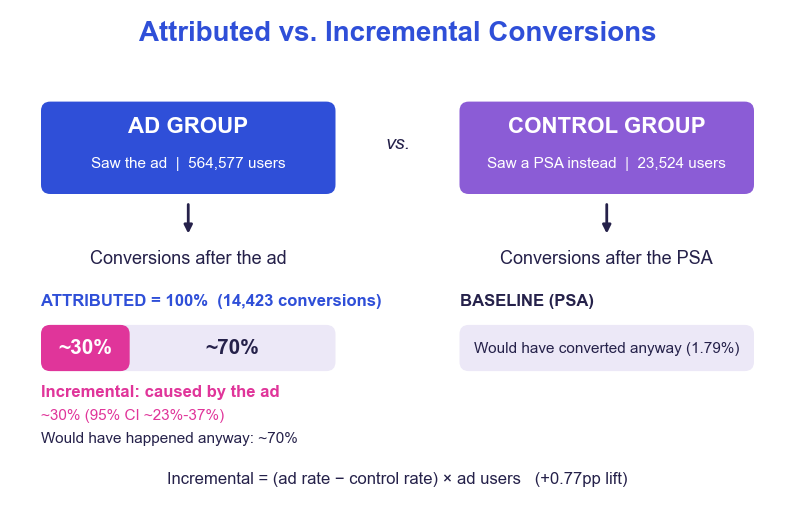

In [14]:
import matplotlib.patches as mpatches

BLUE, PURPLE, PINK, GREY, INK = "#2f4fd8", "#8b5cd6", "#e0359a", "#ece8f7", "#25214a"

fig, ax = plt.subplots(figsize=(10, 6.4))
ax.set_xlim(0, 100)
ax.set_ylim(0, 64)
ax.axis("off")

def box(x, y, w, h, color):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.2",
                                         fc=color, ec="none"))

ax.text(50, 60, "Attributed vs. Incremental Conversions", ha="center", fontsize=20, fontweight="bold", color=BLUE)

# Top row: the two groups and their sizes
box(4, 40, 38, 12, BLUE)
ax.text(23, 48, "AD GROUP", ha="center", fontsize=16, fontweight="bold", color="white")
ax.text(23, 43.5, f"Saw the ad  |  {n_ad:,} users", ha="center", fontsize=11, color="white")
box(58, 40, 38, 12, PURPLE)
ax.text(77, 48, "CONTROL GROUP", ha="center", fontsize=16, fontweight="bold", color="white")
ax.text(77, 43.5, f"Saw a PSA instead  |  {n_psa:,} users", ha="center", fontsize=11, color="white")
ax.text(50, 46, "vs.", ha="center", fontsize=14, style="italic", color=INK)

for x in (23, 77):
    ax.annotate("", xy=(x, 34.5), xytext=(x, 39), arrowprops=dict(arrowstyle="-|>", color=INK, lw=2))
ax.text(23, 31, "Conversions after the ad", ha="center", fontsize=13, color=INK)
ax.text(77, 31, "Conversions after the PSA", ha="center", fontsize=13, color=INK)

# Left: attributed conversions split into incremental (pink) and would-have-happened-anyway (grey)
ax.text(4, 25.5, f"ATTRIBUTED = 100%  ({attributed:,} conversions)", fontsize=12, fontweight="bold", color=BLUE)
bar_w = 38
box(4, 17, bar_w, 6, GREY)
box(4, 17, bar_w * share, 6, PINK)
ax.text(4 + bar_w * share / 2, 20, f"~{share:.0%}", ha="center", va="center", fontsize=15, fontweight="bold", color="white")
ax.text(4 + bar_w * share + (bar_w * (1 - share)) / 2, 20, f"~{1 - share:.0%}", ha="center", va="center",
        fontsize=15, fontweight="bold", color=INK)
ax.text(4, 13.8, "Incremental: caused by the ad", fontsize=12, fontweight="bold", color=PINK)
ax.text(4, 10.8, f"~{share:.0%} (95% CI ~{share_low:.0%}-{share_high:.0%})", fontsize=11, color=PINK)
ax.text(4, 7.8, f"Would have happened anyway: ~{1 - share:.0%}", fontsize=11, color=INK)

# Right: the PSA group's baseline
ax.text(58, 25.5, "BASELINE (PSA)", fontsize=12, fontweight="bold", color=INK)
box(58, 17, 38, 6, GREY)
ax.text(77, 20, f"Would have converted anyway ({rate_psa:.2%})", ha="center", va="center", fontsize=11, color=INK)

ax.text(50, 2.5, f"Incremental = (ad rate \u2212 control rate) \u00d7 ad users   (+{lift * 100:.2f}pp lift)",
        ha="center", fontsize=12, color=INK)

fig.savefig("figures/attributed_vs_incremental.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading it:** the platform would report all of the attributed conversions as the ad's work, but only about 30% were incremental. The rest is the baseline rate the PSA group shows.

## 6. Power: the smallest lift this design could detect
**Plain language:** with 23,524 control users and a 24-to-1 split, what is the smallest true lift we would catch 80% of the time at alpha = 0.05? This uses the design and the observed PSA baseline, not the observed lift, so it is not circular. It is also computed after the fact, so it describes the design rather than guiding it.

In [15]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

power_calc = NormalIndPower()
ratio = n_ad / n_psa      # statsmodels' ratio = size of group 2 / size of group 1 (control is group 1)

# Solve for the effect size (Cohen's h) that gives 80% power with these group sizes
h = power_calc.solve_power(effect_size=None, nobs1=n_psa, alpha=0.05, power=0.80, ratio=ratio,
                           alternative="two-sided")

# Cohen's h is defined as 2*arcsin(sqrt(p1)) - 2*arcsin(sqrt(p0)); invert it to get the ad conversion rate
p_min = np.sin(np.arcsin(np.sqrt(rate_psa)) + h / 2) ** 2
mde = p_min - rate_psa

# Sanity check: plugging that rate back in should give 80% power
check = power_calc.power(effect_size=proportion_effectsize(p_min, rate_psa), nobs1=n_psa, alpha=0.05, ratio=ratio)
print(f"minimum detectable lift = {mde * 100:.2f} pp (power check: {check:.2f})")
print(f"observed lift = {lift * 100:.2f} pp, about {lift / mde:.1f}x the minimum detectable lift")

minimum detectable lift = 0.26 pp (power check: 0.80)
observed lift = 0.77 pp, about 3.0x the minimum detectable lift


**Reading it:** the design could reliably detect lifts down to about a quarter of a percentage point, and the observed lift is about three times that, so the test was well powered for the effect we found.

## 7. Segments (descriptive)
**Plain language:** does the lift look different for heavy vs. light ad viewers, or by day? Each segment gets its own lift and test. Because we run many tests, a few could look significant by chance, so raw p-values are adjusted with the Holm correction.

**Caution:** total ads seen and day of most ads are measured after assignment, and the ad itself can change them. These breakdowns describe the data. They are not causal subgroup effects.

In [16]:
from statsmodels.stats.multitest import multipletests

# Bins fixed in the analysis plan (quartile edges of total_ads)
df["ads_bin"] = pd.cut(df["total_ads"], bins=[0, 4, 13, 27, np.inf], labels=["1-4", "5-13", "14-27", "28+"])
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

rows = []
for col, levels in [("ads_bin", ["1-4", "5-13", "14-27", "28+"]), ("most_ads_day", days)]:
    for level in levels:
        seg = df[df[col] == level]
        a, c = seg[seg["test_group"] == "ad"]["converted"], seg[seg["test_group"] == "psa"]["converted"]
        _, p = proportions_ztest([a.sum(), c.sum()], [len(a), len(c)])
        lo, hi = confint_proportions_2indep(a.sum(), len(a), c.sum(), len(c), method="wald")
        rows.append({"segment": f"{col}: {level}", "n_ad": len(a), "n_psa": len(c),
                     "lift_pp": (a.mean() - c.mean()) * 100, "ci_low_pp": lo * 100, "ci_high_pp": hi * 100,
                     "p_raw": p})

segments = pd.DataFrame(rows)
# Holm controls the chance of any false positive across all segment tests, and is less conservative than Bonferroni
segments["p_holm"] = multipletests(segments["p_raw"], method="holm")[1]
segments["significant_after_holm"] = segments["p_holm"] < 0.05
# Show p-values in scientific form so very small ones do not round to 0.0000
segments.assign(p_raw=segments["p_raw"].map("{:.2g}".format), p_holm=segments["p_holm"].map("{:.2g}".format)).round(3)

,segment,n_ad,n_psa,lift_pp,ci_low_pp,ci_high_pp,p_raw,p_holm,significant_after_holm
0,ads_bin: 1-4,141938,6582,0.039,-0.072,0.149,0.53,1,False
1,ads_bin: 5-13,144957,6019,-0.118,-0.322,0.085,0.21,0.84,False
2,ads_bin: 14-27,137483,5274,-0.065,-0.371,0.240,0.67,1,False
3,ads_bin: 28+,140199,5649,2.991,2.386,3.596,1.1e-15,1.2e-14,True
4,most_ads_day: Monday,83571,3502,1.068,0.562,1.575,0.00051,0.0041,True
5,most_ads_day: Tuesday,74572,2907,1.599,1.148,2.050,6.6e-07,6.6e-06,True
6,most_ads_day: Wednesday,77418,3490,0.960,0.532,1.387,0.00038,0.0034,True
7,most_ads_day: Thursday,79077,3905,0.141,-0.312,0.594,0.55,1,False
8,most_ads_day: Friday,88805,3803,0.616,0.202,1.030,0.012,0.069,False
9,most_ads_day: Saturday,78802,2858,0.731,0.289,1.173,0.0075,0.052,False


**Reading it:** after Holm correction the lift is clearly positive for the heaviest viewers (28+ ads, about +3pp) and on Monday, Tuesday and Wednesday. It is not distinguishable from zero for lighter viewers or on Thursday and Sunday, and Friday and Saturday are borderline (adjusted p just above 0.05). Because total ads is measured after assignment, and the ad can itself change how many ads someone sees, this is a description of where the lift shows up, not evidence that heavy viewers "respond more".

## Limits
- **Control saw a PSA, not no ad.** The estimate is the ad's effect *relative to a PSA*, not relative to no ad at all.
- **Unknown data origin.** How the dataset was collected, and how users were assigned, is not documented.
- **Random assignment and no interference are assumed, not verified.** The balance checks cannot prove randomization, and the columns they use are measured after assignment.
- **Unbalanced split, intended ratio unknown.** A sample ratio mismatch test cannot be run. The 96/4 split costs precision, not validity, if assignment was random.
- **One outcome.** Only conversion is measured: no revenue, no longer-run behavior.
- **No cost data, so no ROI.** Incremental conversions are counted, but whether the campaign paid off is not known.
- **Segments are descriptive,** not causal subgroup effects.